# AgroPest-12 -- YOLOv26-m: Training, Evaluation & Error Analysis

**Student:** Md. Sadik Shahriar  
**Student ID:** 2023-2-60-103  
**Model:** YOLOv26-medium (`yolo26m.pt` -- 20.4M params, 68.2 GFLOPs)  
**Dataset:** AgroPest-12-Cleaned (13,107 images, 12 pest classes, 640x640)  
**Course:** CSE 445 -- Computer Vision | Assignment 1  
**Platform:** Kaggle -- 2x Tesla T4 GPUs (15 GB VRAM each)  

---

This notebook trains YOLOv26-m on the cleaned AgroPest-12 dataset, evaluates on the held-out
test split, and performs error analysis with false-negative, false-positive, misclassification,
and localization-error examples.

In [1]:
# ============================================================
# CONFIG -- YOLOv26-m Training & Evaluation Parameters
# Every parameter below must be justifiable in the viva.
# ============================================================
import os

# ---- Dataset ----
CLEANED_PATH = "/kaggle/input/datasets/sadikshahriar/agropest-12-cleaned/AgroPest-12-Cleaned"
DATA_YAML    = "/kaggle/working/data.yaml"
CLASS_NAMES  = [
    "Ants", "Bees", "Beetles", "Caterpillars",
    "Earthworms", "Earwigs", "Grasshoppers", "Moths",
    "Slugs", "Snails", "Wasps", "Weevils"
]
NUM_CLASSES  = 12

# ---- Model ----
MODEL_NAME   = "yolo26m.pt"
PROJECT      = "/kaggle/working/agropest_yolov26_train"
RUN_NAME     = "yolov26_agropest"

# ============================================================
# MODEL-SIZE JUSTIFICATION
#
# AgroPest-12-Cleaned contains 13,107 images, placing it in the
# 8,000-20,000 bracket per the assignment model-size table (Section 4.1).
#
#   s (small):  Insufficient capacity for 12 classes; validation mAP
#              would plateau early given the class diversity.
#   m (medium): BALANCED CHOICE. Enough capacity for 12-class
#              detection without overfitting. 50 epochs x ~8 min/epoch
#              ~6.7 h -- fits within 9 h Kaggle session limit.
#   l (large):  50 epochs would exceed the 9 h session limit at this
#              dataset size (per Section 4.2 time estimates).
#
# ============================================================

# ---- Training hyperparameters ----
EPOCHS        = 50
BATCH         = 32              # 16 per GPU on 2xT4; YOLOv26-m 
                                
IMGSZ         = 640             # Native dataset resolution; EDA showed 88.9%
                                # of boxes are >96 px -- 1280 unnecessary
DEVICE        = [0, 1]          # DDP across both T4 GPUs
AMP           = True            # FP16 halves VRAM, critical for T4
OPTIMIZER     = "auto"          # >10k iterations -> MuSGD with lr=0.01
LR0           = 0.01            # Auto-adjusted by optimizer='auto' + nbs
LRF           = 0.01            # Final LR = lr0 * lrf = 1e-4
MOMENTUM      = 0.937           # MuSGD momentum for non-orthogonalised layers
WEIGHT_DECAY  = 0.0005          # L2 regularisation weight
WARMUP_EPOCHS = 3.0             # 3 warmup epochs stabilises early gradients
WARMUP_MOMENTUM = 0.8           # Ramps from 0.8 to 0.937 during warmup
WARMUP_BIAS_LR  = 0.1           # Separate lower LR for bias terms during warmup

# ---- Augmentation ----
CLOSE_MOSAIC  = 10              # Disable mosaic last 10 epochs -> tighter boxes
MOSAIC        = 1.0             # Multi-image context helps rare classes;
                                # EDA showed >2:1 class imbalance
MIXUP         = 0.15            # Mild label mixing flattens class imbalance;
                                # kept low to avoid confusing small pest features
DEGREES       = 10.0            # Pests appear at arbitrary orientations in field
SCALE         = 0.5             # 0.75x-1.25x scaling covers natural size variation
SHEAR         = 0.0             # Shear distorts insect morphology -- excluded
TRANSLATE     = 0.1             # Partially-visible insects at image edges
FLIPLR        = 0.5             # No semantic meaning to left/right orientation
FLIPUD        = 0.5             # Pests can appear at any angle relative to a top-down camera
HSV_H         = 0.01            # REDUCED from default 0.015 -- colour is key
                                # species identifier; minimal hue jitter
HSV_S         = 0.4             # REDUCED from default 0.7 -- preserves
                                # colour-based class distinctions (e.g., green
                                # grasshopper vs brown moth)
HSV_V         = 0.4             # Brightness variation for outdoor field lighting

# ---- Regularisation & Scheduling ----
RECT          = False           # All images are 640x640 square -- no padding
COS_LR        = False           # Linear LR decay works well with MuSGD
PATIENCE      = 25              # Early-stop on mAP@50:95 per Section 4.3.1
                                # recommendation (20-30 epochs)
NBS           = 64              # Nominal batch for LR scaling; accumulate =
                                # ceil(64/32) = 2 -> effective batch ~64
WORKERS       = 4               # 2 dataloader workers per GPU

# ---- Inference ----
CONF          = 0.25            # Standard eval confidence threshold
IOU           = 0.7             # IoU threshold for mAP evaluation matching (YOLOv26 is NMS-free -- no NMS applied at inference)
MAX_DET       = 300             # Max detections per image

print("CONFIG loaded -- YOLOv26-m | 50 epochs | batch=32 | 640x640 | 2xT4 DDP")

CONFIG loaded -- YOLOv26-m | 50 epochs | batch=32 | 640x640 | 2xT4 DDP


# Environment Setup

In [2]:
!pip install ultralytics --no-deps

import torch
import os, yaml, shutil, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.image as mpimg
import cv2
from pathlib import Path
from ultralytics import YOLO
import warnings
warnings.filterwarnings('ignore')

# ---- GPU check ----
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
ngpu = torch.cuda.device_count()
print(f"GPU count: {ngpu}")
for i in range(ngpu):
    props = torch.cuda.get_device_properties(i)
    # Changed 'total_mem' to 'total_memory' below:
    print(f"  GPU {i}: {torch.cuda.get_device_name(i)} | "
          f"{props.total_memory / 1024**3:.1f} GB VRAM")

# ---- Plot styling ----
plt.rcParams.update({
    'figure.dpi': 100,
    'savefig.dpi': 100,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

# Distinct colours for 12 classes
CLASS_COLORS = [
    "#e6194b", "#3cb44b", "#ffe119", "#4363d8",
    "#f58231", "#911eb4", "#46f0f0", "#f032e6",
    "#bcf60c", "#fabebe", "#008080", "#e6beff"
]

print("\nEnvironment ready.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 19.1 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PyTorch version: 2.10.0+cu128
CUDA available: True
GPU count: 2
  GPU 0: Tesla T4 | 14.6 GB VRAM
  GPU 1: Tesla T4 | 14.6 GB VRAM

Environment ready.


# Data Load

Generate a `data.yaml` pointing to the AgroPest-12-Cleaned dataset on Kaggle.
All training notebooks (2-5) use this cleaned dataset, which has 36 mislabeled
image-label pairs removed (0.27% of original 13,143 files). See Notebook 1 for
the full label-quality audit.

**Split counts after cleaning:**
- Train: 11,475 images (27 removed)
- Valid: 1,089 images (6 removed)
- Test:   543 images (3 removed)

In [3]:
from ultralytics import YOLO
import yaml
from pathlib import Path

# ------------------------------------------------------------
# Generate data.yaml with absolute Kaggle paths
# ------------------------------------------------------------

# Verify the cleaned dataset directory exists
assert os.path.isdir(CLEANED_PATH), f"Cleaned dataset not found at {CLEANED_PATH}"
for sub in ["train/images", "train/labels", "valid/images", "valid/labels",
            "test/images", "test/labels"]:
    p = os.path.join(CLEANED_PATH, sub)
    assert os.path.isdir(p), f"Missing directory: {p}"

# Print split sizes
for split in ["train", "valid", "test"]:
    n_img = len(os.listdir(os.path.join(CLEANED_PATH, split, "images")))
    n_lbl = len(os.listdir(os.path.join(CLEANED_PATH, split, "labels")))
    print(f"  {split:>6}: {n_img:>5} images | {n_lbl:>5} labels")

# Write data.yaml
data_config = {
    "train": os.path.join(CLEANED_PATH, "train", "images"),
    "val":   os.path.join(CLEANED_PATH, "valid", "images"),
    "test":  os.path.join(CLEANED_PATH, "test", "images"),
    "nc":    NUM_CLASSES,
    "names": CLASS_NAMES,
}

yaml_path = Path(DATA_YAML)
with open(yaml_path, "w") as f:
    yaml.dump(data_config, f, default_flow_style=False, sort_keys=False)

# Load and print to confirm
with open(yaml_path, "r") as f:
    data_cfg = yaml.safe_load(f)

print(f"\nDataset loaded successfully from: {CLEANED_PATH}")
print("-" * 40)
print(yaml.dump(data_cfg, sort_keys=False))

   train: 11475 images | 11475 labels
   valid:  1089 images |  1089 labels
    test:   543 images |   543 labels

Dataset loaded successfully from: /kaggle/input/datasets/sadikshahriar/agropest-12-cleaned/AgroPest-12-Cleaned
----------------------------------------
train: /kaggle/input/datasets/sadikshahriar/agropest-12-cleaned/AgroPest-12-Cleaned/train/images
val: /kaggle/input/datasets/sadikshahriar/agropest-12-cleaned/AgroPest-12-Cleaned/valid/images
test: /kaggle/input/datasets/sadikshahriar/agropest-12-cleaned/AgroPest-12-Cleaned/test/images
nc: 12
names:
- Ants
- Bees
- Beetles
- Caterpillars
- Earthworms
- Earwigs
- Grasshoppers
- Moths
- Slugs
- Snails
- Wasps
- Weevils



# Train Model

Training YOLOv26-m for 50 epochs on 11,475 clean training images.
Validation runs every epoch on the 1,089-image valid split. The best
checkpoint is saved automatically (fitness = 0.1*mAP50 + 0.9*mAP50-95).

**Key configuration notes:**
- Mosaic augmentation is disabled for the last 10 epochs (`close_mosaic=10`)
  to refine box regression on real (un-augmented) images (Section 4.3.2).
- Mixup (0.15) is enabled to help with class imbalance identified in EDA.
- HSV saturation is reduced from 0.7 to 0.4 to preserve colour-based
  species distinctions (e.g., green grasshopper vs brown moth).
- Early stopping monitors mAP@50:95 with patience=25 (Section 4.3.1).
- `optimizer='auto'` selects MuSGD with lr=0.01 for runs >10k iterations.

**Key differences from YOLOv12:**
- YOLOv26 uses a NMS-free end-to-end architecture with a dual-head design,
  eliminating traditional Non-Maximum Suppression during inference.
- YOLOv26 removes Distribution Focal Loss (DFL) entirely for a lighter
  detection head with unconstrained regression range.
- YOLOv26 incorporates Progressive Loss (ProgLoss) for better supervision
  and STAL (Small-Target-Aware Label Assignment) for small-object detection.

In [4]:
#Sometimes, when a long training run starts, YOLO pauses in the console and asks you to paste a WandB API key. If you walk away from your computer, the training will just sit there waiting forever, burning your GPU quota.
import os
os.environ["WANDB_MODE"] = "disabled"

In [5]:
model = YOLO(MODEL_NAME)  # pre-trained model

results = model.train(
    data=str(yaml_path),
    epochs=EPOCHS,
    batch=BATCH,
    imgsz=IMGSZ,
    device=DEVICE,
    amp=AMP,
    optimizer=OPTIMIZER,
    lr0=LR0,
    lrf=LRF,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
    warmup_epochs=WARMUP_EPOCHS,
    warmup_momentum=WARMUP_MOMENTUM,
    warmup_bias_lr=WARMUP_BIAS_LR,
    close_mosaic=CLOSE_MOSAIC,
    mosaic=MOSAIC,
    mixup=MIXUP,
    degrees=DEGREES,
    scale=SCALE,
    shear=SHEAR,
    translate=TRANSLATE,
    fliplr=FLIPLR,
    flipud=FLIPUD,
    hsv_h=HSV_H,
    hsv_s=HSV_S,
    hsv_v=HSV_V,
    rect=RECT,
    cos_lr=COS_LR,
    patience=PATIENCE,
    nbs=NBS,
    workers=WORKERS,
    project=PROJECT,
    name=RUN_NAME,
    exist_ok=True,
    val=True,
    plots=True,
    save=True,
)

print("\nTraining complete. Best model saved in:")
best_pt = os.path.join(PROJECT, RUN_NAME, "weights", "best.pt")
print(best_pt)

Ultralytics 8.4.84 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                       CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=10.0, deterministic=True, device=0,1, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.4, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov26_agropest, n

# Model Performance

Ultralytics auto-generates training curves and validation metrics during
training. The plots below show loss components (box, cls, dfl) and
detection metrics (Precision, Recall, mAP@50, mAP@50:95) across all epochs.

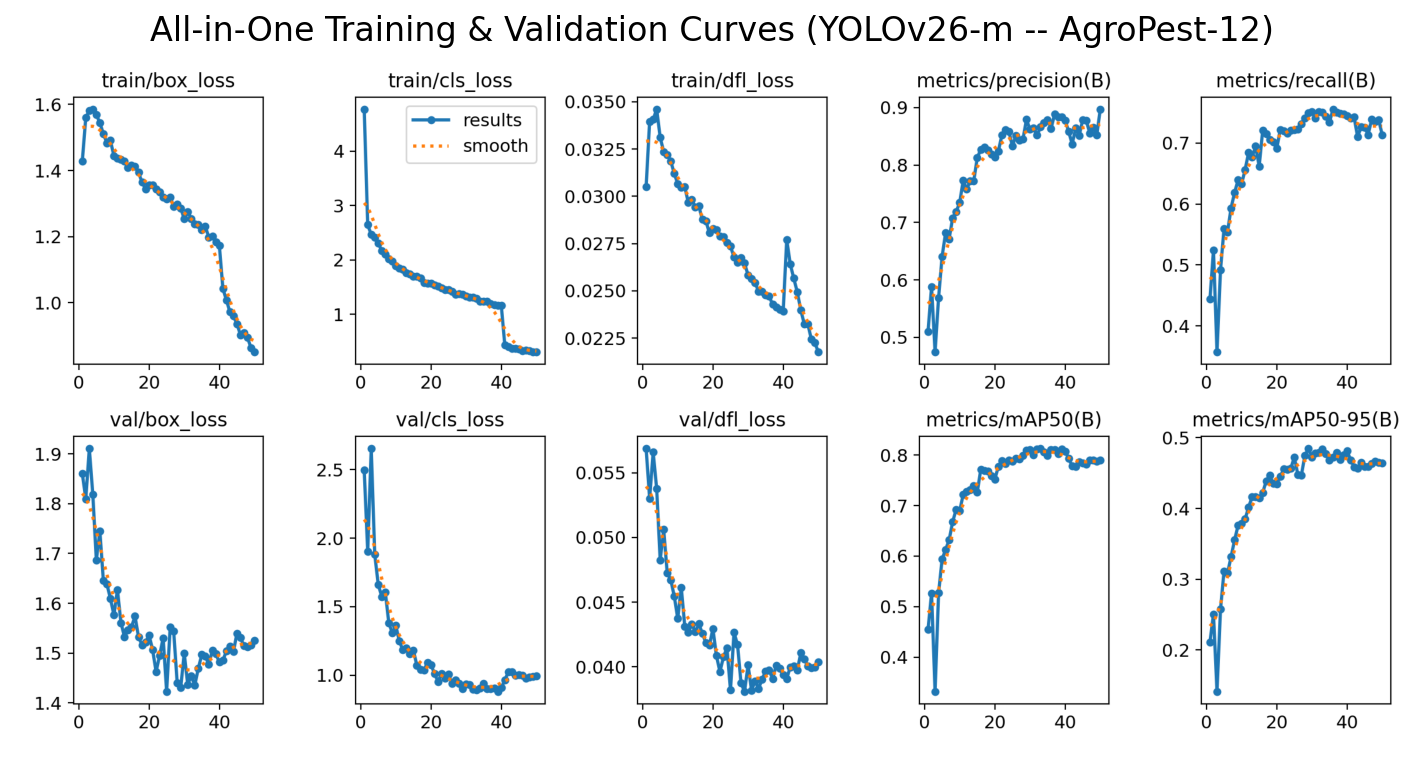

In [6]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os
from IPython.display import Image, display

# --- 1. Define paths and title ---
results_dir = os.path.join(PROJECT, RUN_NAME)
image_filename = "results.png"
image_path = os.path.join(results_dir, image_filename)

my_custom_title = "All-in-One Training & Validation Curves (YOLOv26-m -- AgroPest-12)"

# --- 2. Load and display the image with a matplotlib title ---
try:
    img = mpimg.imread(image_path)
    plt.figure(figsize=(12, 10), dpi=150)
    plt.imshow(img)
    plt.title(my_custom_title, fontsize=16)
    plt.axis('off')
    plt.show()
except FileNotFoundError:
    print(f"Error: Could not find '{image_filename}' in {results_dir}")
    print("Please make sure the 'results_dir' path is correct.")

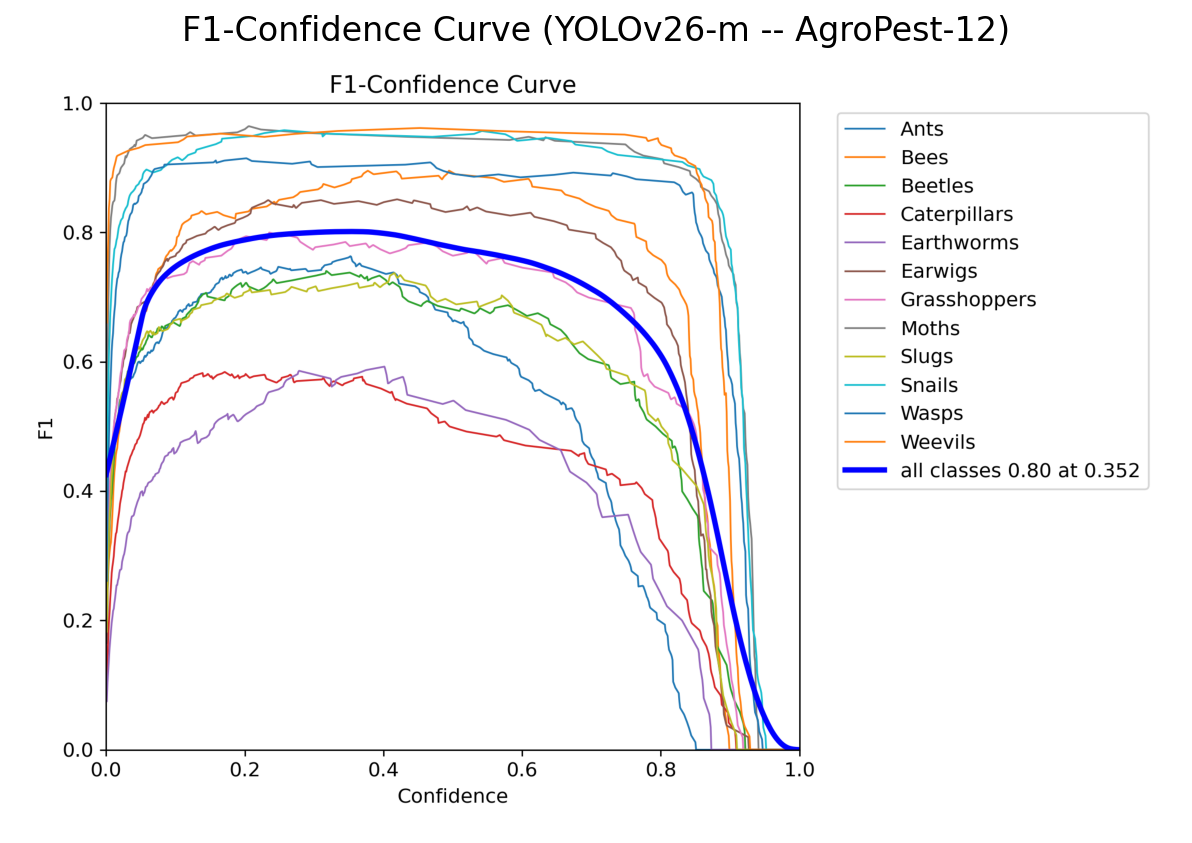

In [7]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

# --- 1. Define paths and title ---
results_dir = os.path.join(PROJECT, RUN_NAME)
image_filename = "BoxF1_curve.png"
image_path = os.path.join(results_dir, image_filename)

my_custom_title = "F1-Confidence Curve (YOLOv26-m -- AgroPest-12)"

# --- 2. Load and display ---
try:
    img = mpimg.imread(image_path)
    plt.figure(figsize=(10, 8), dpi=150)
    plt.imshow(img)
    plt.title(my_custom_title, fontsize=16)
    plt.axis('off')
    plt.show()
except FileNotFoundError:
    print(f"Error: Could not find '{image_filename}' in {results_dir}")

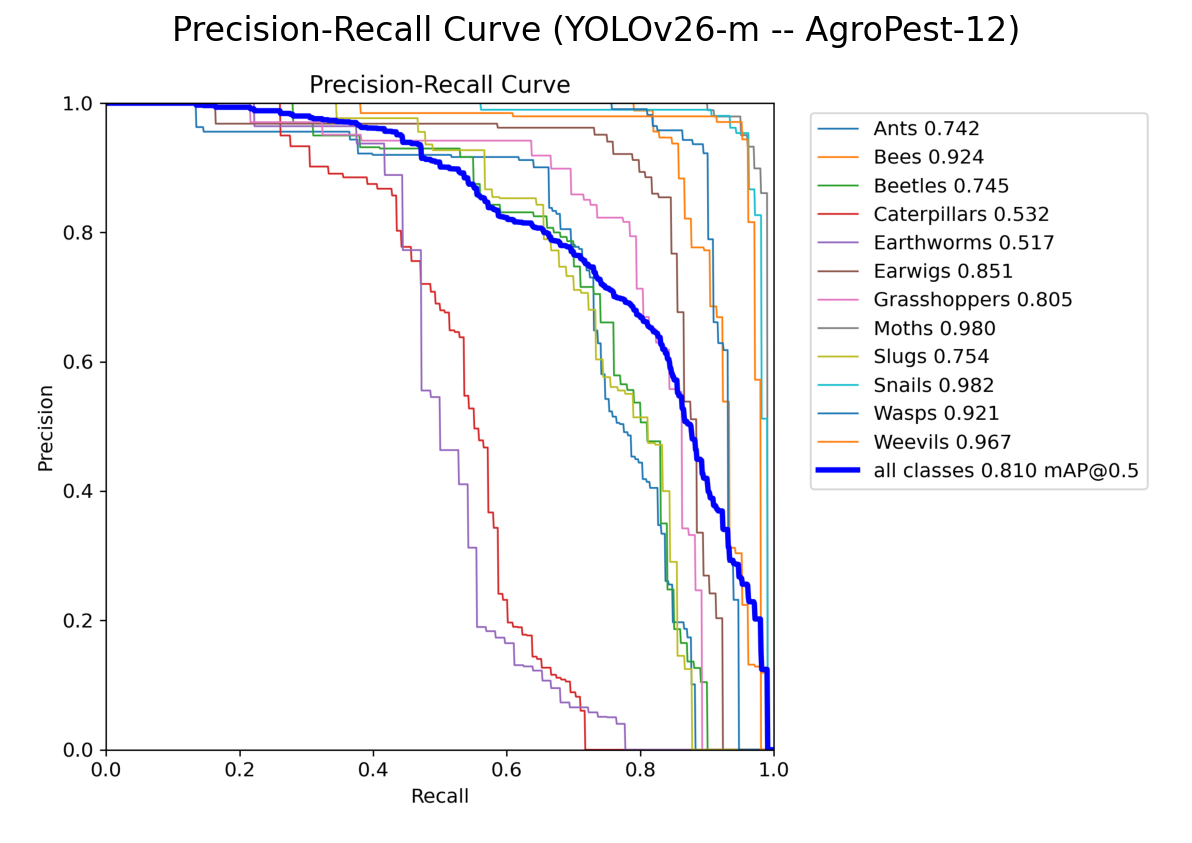

In [8]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

# --- 1. Define paths and title ---
results_dir = os.path.join(PROJECT, RUN_NAME)
image_filename = "BoxPR_curve.png"
image_path = os.path.join(results_dir, image_filename)

my_custom_title = "Precision-Recall Curve (YOLOv26-m -- AgroPest-12)"

# --- 2. Load and display ---
try:
    img = mpimg.imread(image_path)
    plt.figure(figsize=(10, 8), dpi=150)
    plt.imshow(img)
    plt.title(my_custom_title, fontsize=16)
    plt.axis('off')
    plt.show()
except FileNotFoundError:
    print(f"Error: Could not find '{image_filename}' in {results_dir}")

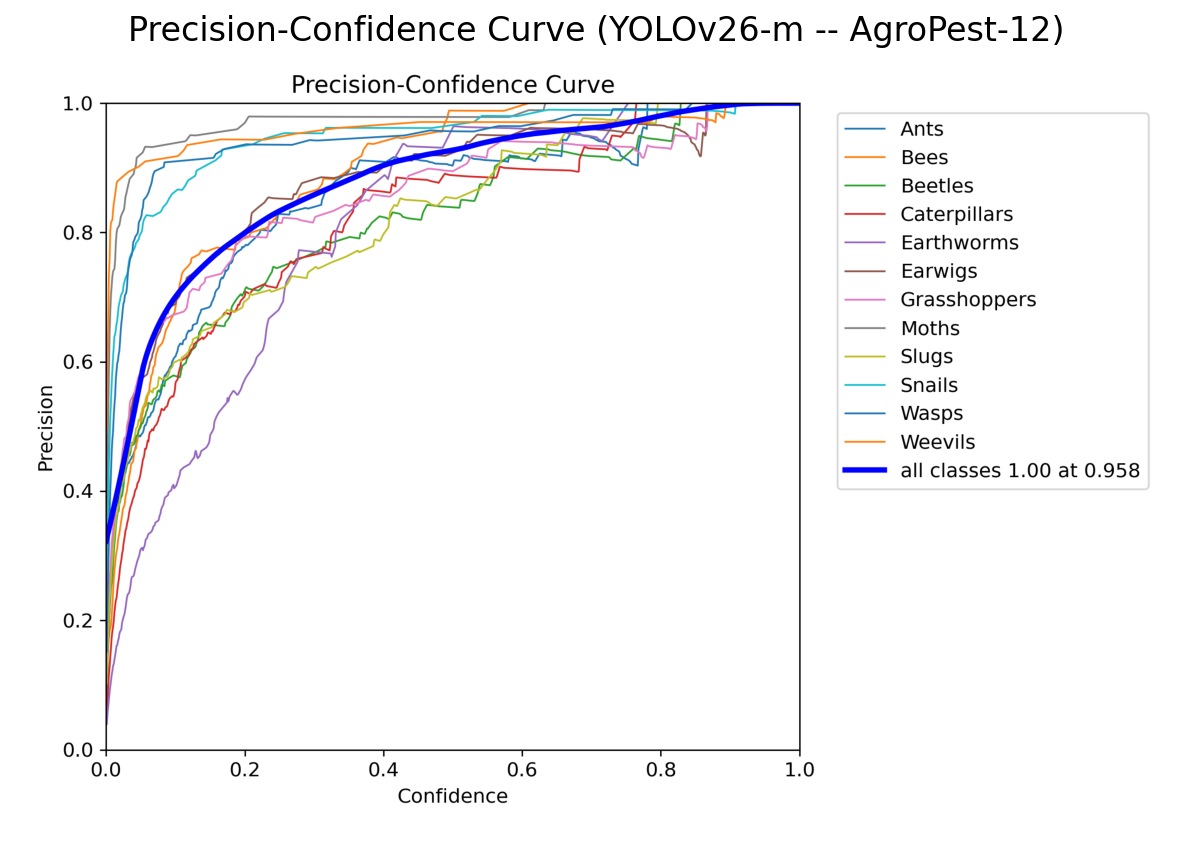

In [9]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

# --- 1. Define paths and title ---
results_dir = os.path.join(PROJECT, RUN_NAME)
image_filename = "BoxP_curve.png"
image_path = os.path.join(results_dir, image_filename)

my_custom_title = "Precision-Confidence Curve (YOLOv26-m -- AgroPest-12)"

# --- 2. Load and display ---
try:
    img = mpimg.imread(image_path)
    plt.figure(figsize=(10, 8), dpi=150)
    plt.imshow(img)
    plt.title(my_custom_title, fontsize=16)
    plt.axis('off')
    plt.show()
except FileNotFoundError:
    print(f"Error: Could not find '{image_filename}' in {results_dir}")

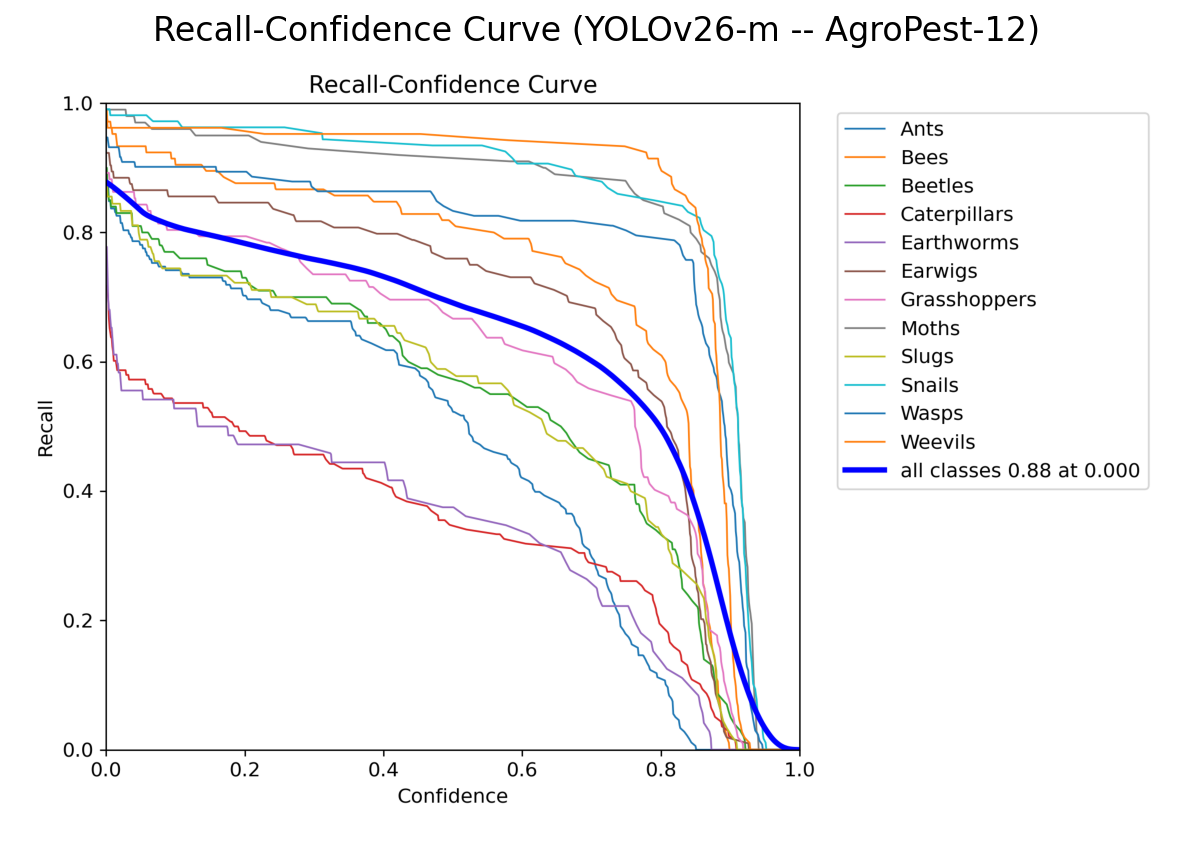

In [10]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

# --- 1. Define paths and title ---
results_dir = os.path.join(PROJECT, RUN_NAME)
image_filename = "BoxR_curve.png"
image_path = os.path.join(results_dir, image_filename)

my_custom_title = "Recall-Confidence Curve (YOLOv26-m -- AgroPest-12)"

# --- 2. Load and display ---
try:
    img = mpimg.imread(image_path)
    plt.figure(figsize=(10, 8), dpi=150)
    plt.imshow(img)
    plt.title(my_custom_title, fontsize=16)
    plt.axis('off')
    plt.show()
except FileNotFoundError:
    print(f"Error: Could not find '{image_filename}' in {results_dir}")

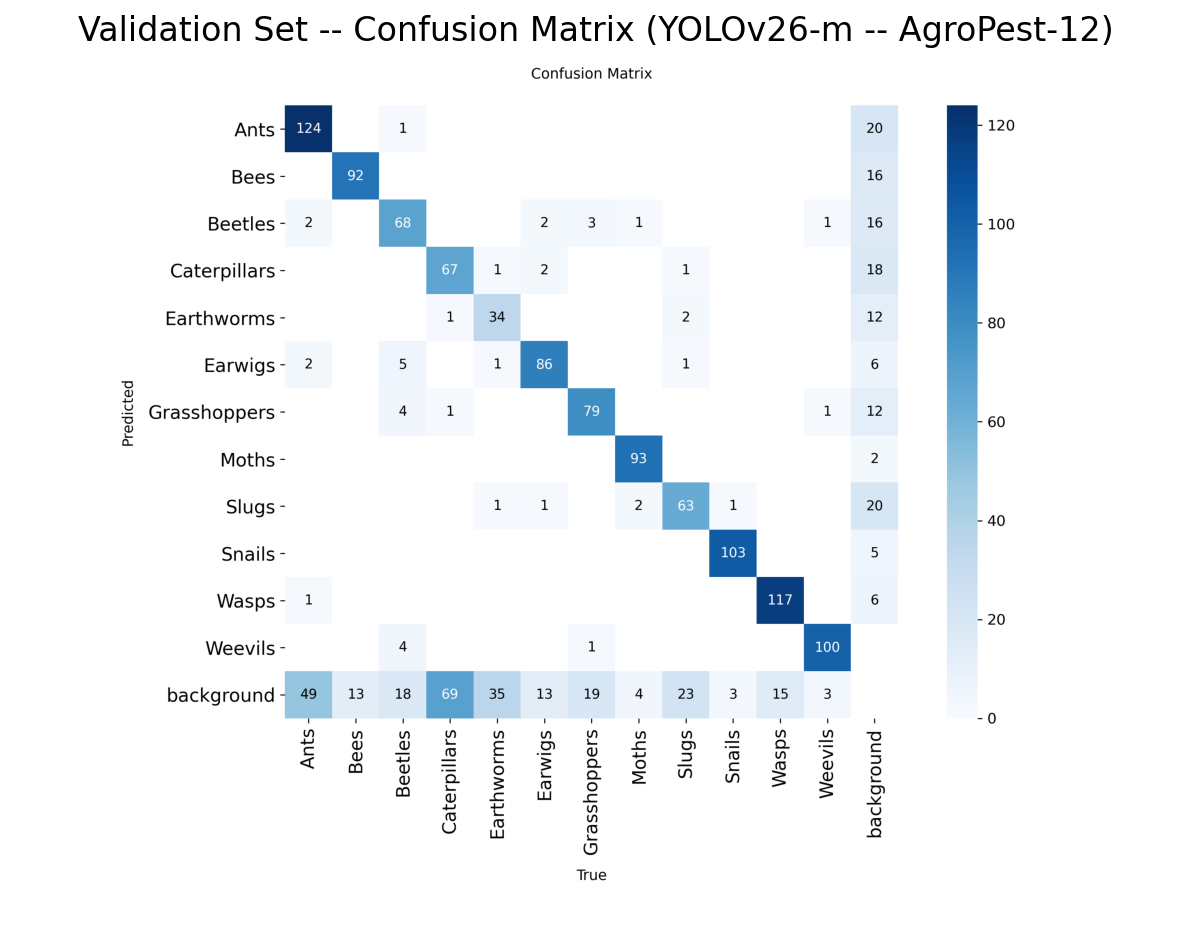

In [11]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

# --- 1. Define paths and title ---
results_dir = os.path.join(PROJECT, RUN_NAME)
image_filename = "confusion_matrix.png"
image_path = os.path.join(results_dir, image_filename)

my_custom_title = "Validation Set -- Confusion Matrix (YOLOv26-m -- AgroPest-12)"

# --- 2. Load and display ---
try:
    img = mpimg.imread(image_path)
    plt.figure(figsize=(10, 8), dpi=150)
    plt.imshow(img)
    plt.title(my_custom_title, fontsize=16)
    plt.axis('off')
    plt.show()
except FileNotFoundError:
    print(f"Error: Could not find '{image_filename}' in {results_dir}")
    print("Please make sure the 'results_dir' path is correct.")

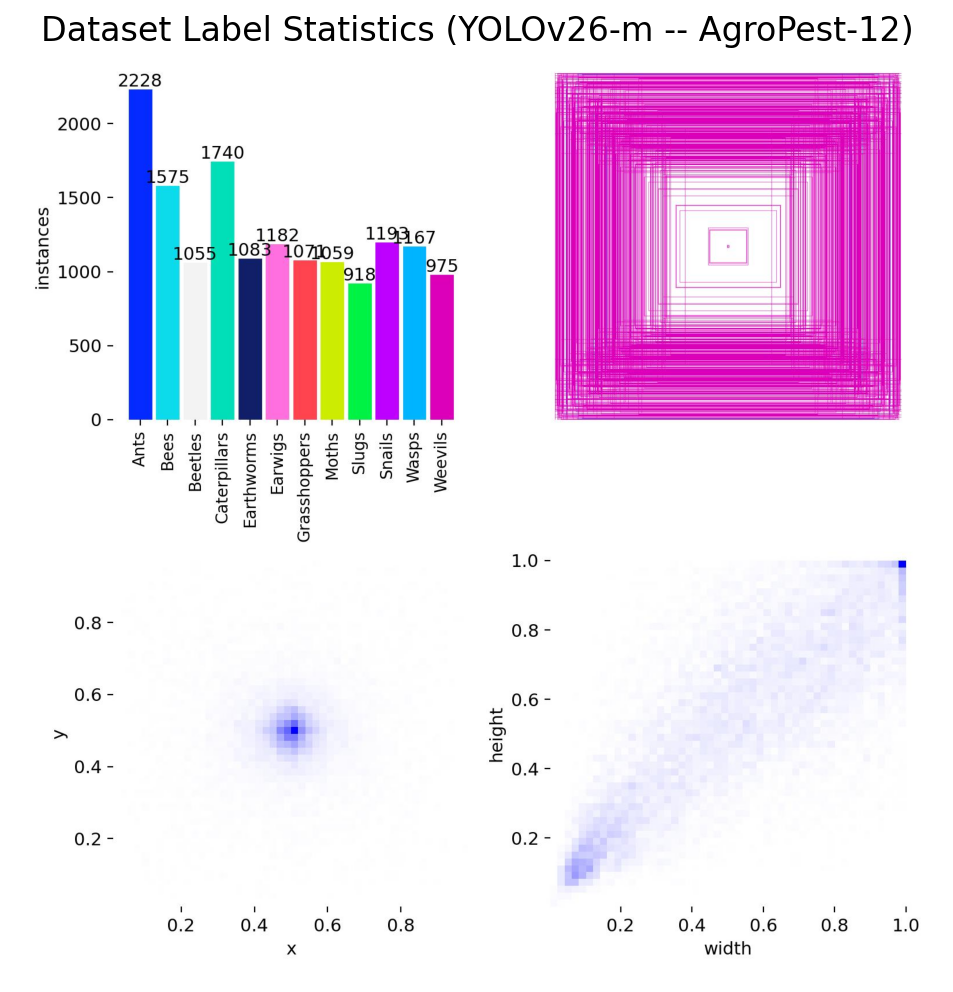

In [12]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

# --- 1. Define paths and title ---
results_dir = os.path.join(PROJECT, RUN_NAME)
image_filename = "labels.jpg"
image_path = os.path.join(results_dir, image_filename)

my_custom_title = "Dataset Label Statistics (YOLOv26-m -- AgroPest-12)"

# --- 2. Load and display ---
try:
    img = mpimg.imread(image_path)
    plt.figure(figsize=(10, 8), dpi=150)
    plt.imshow(img)
    plt.title(my_custom_title, fontsize=16)
    plt.axis('off')
    plt.show()
except FileNotFoundError:
    print(f"Error: Could not find '{image_filename}' in {results_dir}")
    print("Please make sure the 'results_dir' path is correct.")

# Evaluation

Evaluating the best checkpoint on both the validation and test splits.
Metrics reported: Precision, Recall, mAP@50, mAP@50:95, F1-score (mean over
classes). Per-class metrics and inference speed (FPS) are also measured on
the test split. The confusion matrix shows class-level predictions vs ground
truth on the test set.

**Note on YOLOv26 vs YOLOv12 comparison (for viva):**
YOLOv26 uses a NMS-free dual-head architecture with end-to-end inference,
while YOLOv12 relies on attention-based A2C2f blocks with traditional NMS.
YOLOv26 removes Distribution Focal Loss (DFL) for a lighter detection head
and incorporates MuSGD optimizer, Progressive Loss, and STAL for improved
small-object detection. Both models have similar parameter counts (~20M)
and GFLOPs (~68), making them directly comparable on the same hardware.

Loading trained model from:
/kaggle/working/agropest_yolov26_train/yolov26_agropest/weights/best.pt

Using data yaml: /kaggle/working/data.yaml

Evaluating on VALIDATION set...
Ultralytics 8.4.84 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26m summary (fused): 132 layers, 20,358,704 parameters, 0 gradients
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 31.3±13.9 MB/s, size: 34.9 KB)
val: Scanning /kaggle/input/datasets/sadikshahriar/agropest-12-cleaned/AgroPest-12-Cleaned/valid/labels... 1089 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1089/1089 486.9it/s 2.2s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/sadikshahriar/agropest-12-cleaned/AgroPest-12-Cleaned/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 69/69 1.9it/s 36.1s
                   all       1089       1333      0.886      0.747       0.81      0.485
                  Ants         9

,Class,Precision,Recall,mAP@50,mAP@50-95,F1
0,Ants,0.9091,0.7471,0.7867,0.4754,0.8202
1,Bees,0.8845,0.8706,0.7867,0.4754,0.8775
2,Beetles,0.8345,0.6279,0.7867,0.4754,0.7166
3,Caterpillars,0.8582,0.3906,0.7867,0.4754,0.5369
4,Earthworms,0.5922,0.4720,0.7867,0.4754,0.5253
5,Earwigs,0.6937,0.6712,0.7867,0.4754,0.6823
6,Grasshoppers,0.7923,0.5636,0.7867,0.4754,0.6587
7,Moths,0.9761,0.9095,0.7867,0.4754,0.9416
8,Slugs,0.8361,0.7002,0.7867,0.4754,0.7621
9,Snails,0.8911,0.8800,0.7867,0.4754,0.8855



Loading confusion matrix from:
/kaggle/working/runs/detect/val-2/confusion_matrix.png



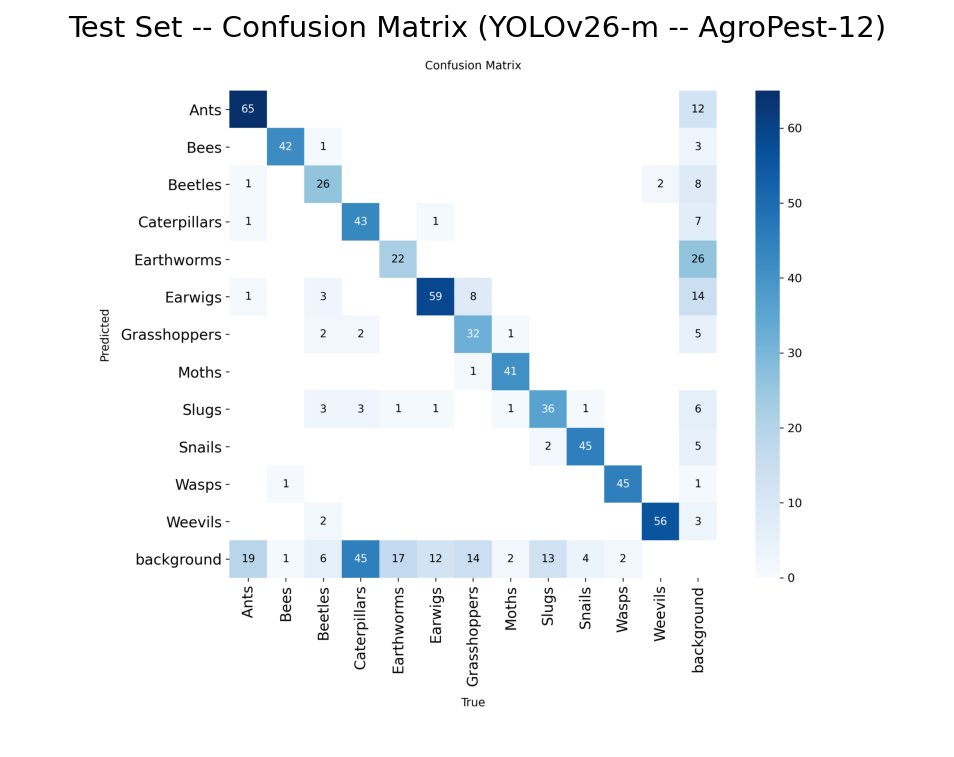


────────────────────────────────────────
  Inference speed (100 images): 3.84 s -> 26.0 FPS
  Per-image time: 38.4 ms


In [13]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from ultralytics import YOLO

# ------------------------------------------------------------
# 0. Load the trained model (best.pt)
# ------------------------------------------------------------
best_model_path = os.path.join(PROJECT, RUN_NAME, "weights", "best.pt")
print(f"Loading trained model from:\n{best_model_path}\n")

model = YOLO(best_model_path)

# yaml_path is already defined in the Data Load cell
print(f"Using data yaml: {yaml_path}\n")

# ------------------------------------------------------------
# 1. Validation Set Evaluation
# ------------------------------------------------------------
print("Evaluating on VALIDATION set...")
with np.errstate(invalid='ignore'):
    val_metrics = model.val(data=str(yaml_path), split="val")

val_p  = float(val_metrics.box.p.mean())
val_r  = float(val_metrics.box.r.mean())
val_map50   = float(val_metrics.box.map50.mean())
val_map5095 = float(val_metrics.box.map.mean())
val_f1 = float(val_metrics.box.f1.mean())

print("\nValidation metrics (mean over classes):")
print(f"  Precision:  {val_p:.4f}")
print(f"  Recall:     {val_r:.4f}")
print(f"  mAP@0.50:   {val_map50:.4f}")
print(f"  mAP@0.50:0.95: {val_map5095:.4f}")
print(f"  F1-score:   {val_f1:.4f}")
print("-" * 40)

# ------------------------------------------------------------
# 2. Test Set Evaluation
# ------------------------------------------------------------
print("\nEvaluating on TEST set...")
with np.errstate(invalid='ignore'):
    test_metrics = model.val(data=str(yaml_path), split="test")

test_p  = float(test_metrics.box.p.mean())
test_r  = float(test_metrics.box.r.mean())
test_map50   = float(test_metrics.box.map50.mean())
test_map5095 = float(test_metrics.box.map.mean())
test_f1 = float(test_metrics.box.f1.mean())

print("\nTest metrics (mean over classes):")
print(f"  Precision:  {test_p:.4f}")
print(f"  Recall:     {test_r:.4f}")
print(f"  mAP@0.50:   {test_map50:.4f}")
print(f"  mAP@0.50:0.95: {test_map5095:.4f}")
print(f"  F1-score:   {test_f1:.4f}")
print("-" * 40)

# ------------------------------------------------------------
# 3. Per-Class Metrics Table (Test Set)
# ------------------------------------------------------------
# Removed .cpu().numpy() because Ultralytics already outputs these as NumPy arrays
per_cls_p     = test_metrics.box.p
per_cls_r     = test_metrics.box.r
per_cls_m50   = test_metrics.box.map50
per_cls_m5095 = test_metrics.box.map
per_cls_f1    = test_metrics.box.f1

df_per_class = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Precision":    np.round(per_cls_p,    4),
    "Recall":       np.round(per_cls_r,    4),
    "mAP@50":       np.round(per_cls_m50,  4),
    "mAP@50-95":    np.round(per_cls_m5095, 4),
    "F1":           np.round(per_cls_f1,   4),
})
print("\nPer-Class Metrics (Test Set):")
display(df_per_class)

# ------------------------------------------------------------
# 4. Confusion Matrix from Test Run
# ------------------------------------------------------------
try:
    results_dir = test_metrics.save_dir
    cm_filename = "confusion_matrix.png"
    cm_path = os.path.join(results_dir, cm_filename)

    print(f"\nLoading confusion matrix from:\n{cm_path}\n")
    img = mpimg.imread(cm_path)

    plt.figure(figsize=(8, 6), dpi=150)
    plt.imshow(img)
    plt.title("Test Set -- Confusion Matrix (YOLOv26-m -- AgroPest-12)", fontsize=14)
    plt.axis('off')
    plt.show()
except FileNotFoundError:
    print(f"Could not find '{cm_filename}' in {results_dir}")

# ------------------------------------------------------------
# 5. Inference Speed (FPS) -- 100 Test Images
# ------------------------------------------------------------
test_img_dir = os.path.join(CLEANED_PATH, "test", "images")
test_images  = sorted(
    [os.path.join(test_img_dir, f) for f in os.listdir(test_img_dir)
     if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
)[:100]

t0 = time.time()
preds = model.predict(
    source=test_images,
    imgsz=IMGSZ,
    device=DEVICE,
    conf=CONF,
    iou=IOU,
    max_det=MAX_DET,
    verbose=False,
)
t_total = time.time() - t0
fps = 100 / t_total
print(f"\n{'─'*40}")
print(f"  Inference speed (100 images): {t_total:.2f} s -> {fps:.1f} FPS")
print(f"  Per-image time: {t_total/100*1000:.1f} ms")

# Model Inference -- Sample Predictions by Class

Run inference using the best checkpoint on the test split. To fairly
assess performance across all 12 pest classes, we select **3 images per
class** (36 images total) from the test set -- each image containing at
least one instance of the target class. Predictions are visualised with
colour-coded bounding boxes and class labels.

The grid below helps identify class-specific failure patterns
(e.g., confusion between visually similar species like Slugs vs Snails)
before formal error analysis.

Images selected per class:
           Ants: 3
           Bees: 3
        Beetles: 3
   Caterpillars: 3
     Earthworms: 3
        Earwigs: 3
   Grasshoppers: 3
          Moths: 3
          Slugs: 3
         Snails: 3
          Wasps: 3
        Weevils: 3

Running inference on 35 images...


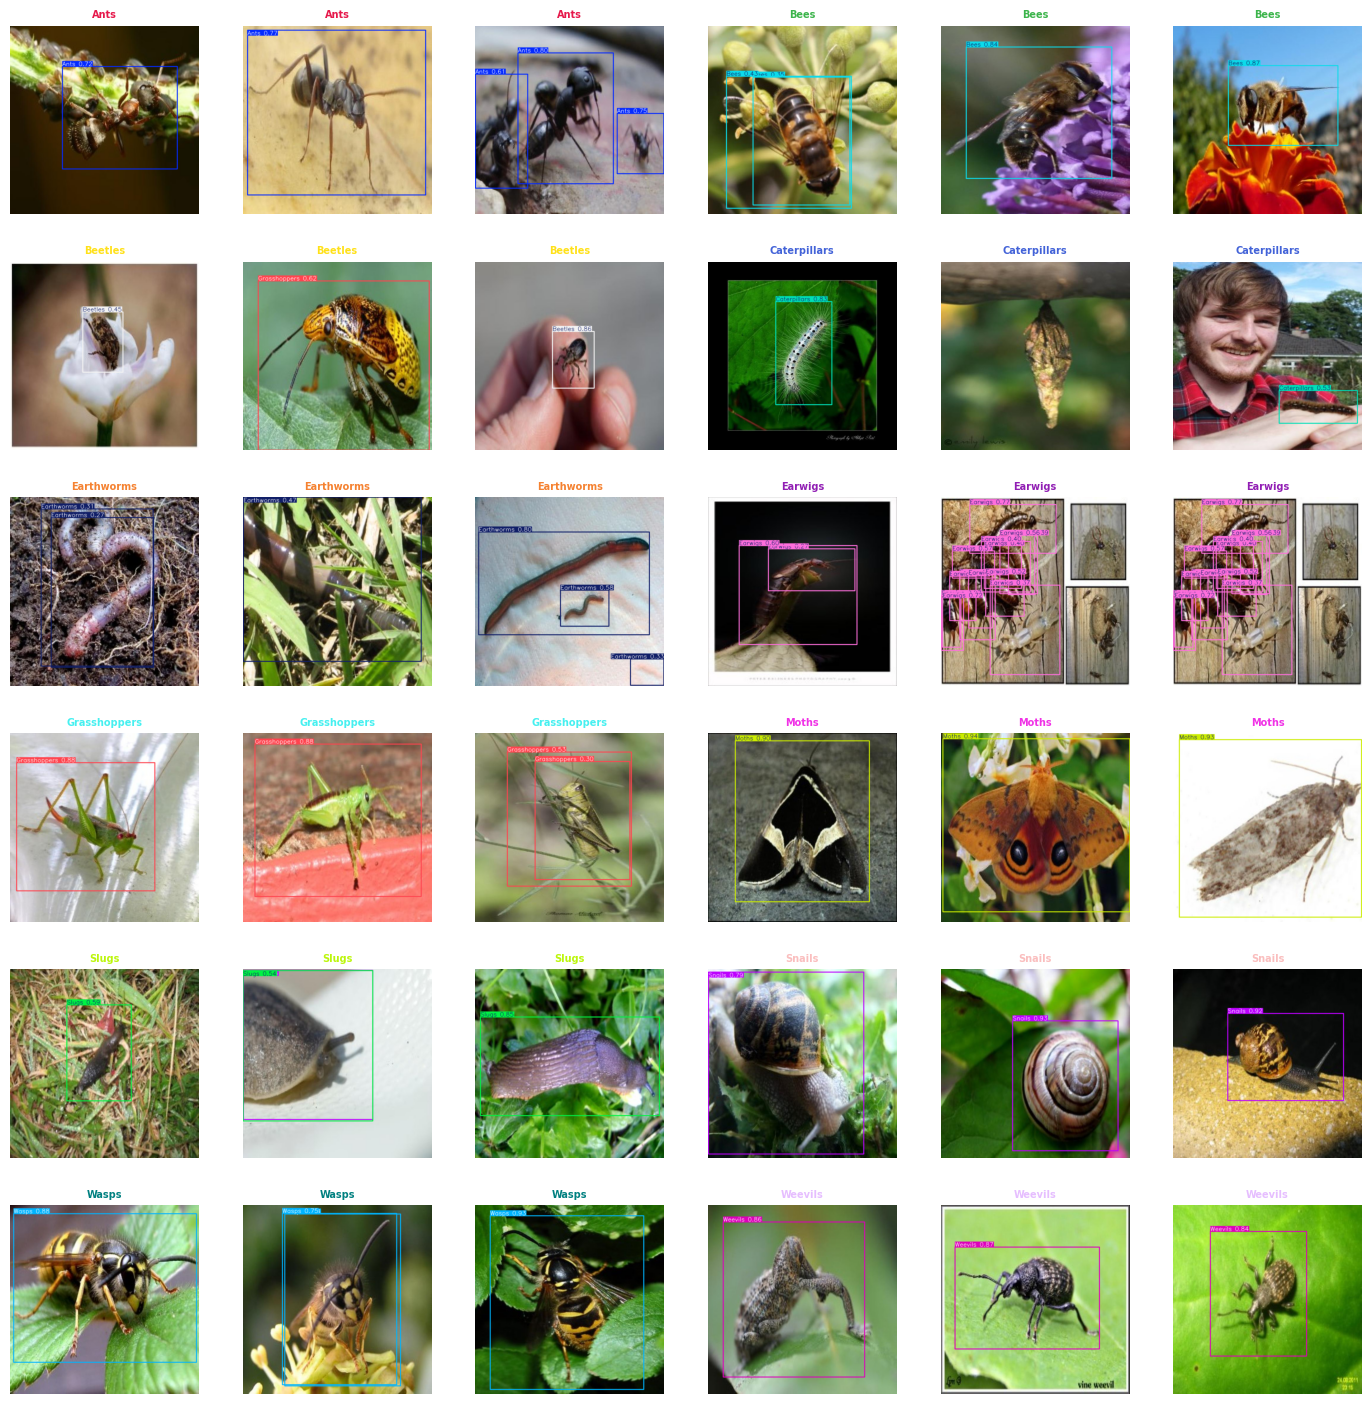


  INFERENCE CORRECTNESS LOG -- Per-Image
  [OK]           Ants | ants-112-_jpg.rf.b8d6b9acf9fa1edfb4 | GT:{0}  Pred:{0}
  [OK]           Ants | ants-122-_jpg.rf.4819e9d7a1531a8b3a | GT:{0}  Pred:{0}
  [OK]           Ants | ants-138-_jpg.rf.1910f63385ebe67408 | GT:{0}  Pred:{0}
  [MISS]          Bees | bees-112-_jpg.rf.24609662f0f1e1507a | GT:{1}  Pred:{1}
  [OK]           Bees | bees-114-_jpg.rf.f11f411da6d22748c8 | GT:{1}  Pred:{1}
  [OK]           Bees | bees-119-_jpg.rf.001c0fd7e4c24a50fe | GT:{1}  Pred:{1}
  [OK]        Beetles | beetle-105-_jpg.rf.c32afee834200fcc | GT:{2}  Pred:{2}
  [MISS]       Beetles | beetle-120-_jpg.rf.20173f98d8473d43 | GT:{2}  Pred:{6}
  [OK]        Beetles | beetle-127-_jpg.rf.77ebf94f40f0602b | GT:{2}  Pred:{2}
  [MISS]  Caterpillars | catterpillar-100-_jpg.rf.6308bf1bee | GT:{3}  Pred:{3}
  [MISS]  Caterpillars | catterpillar-101-_jpg.rf.d74e8623b0 | GT:{3}  Pred:set()
  [OK]   Caterpillars | catterpillar-122-_jpg.rf.8006cda415 | GT:{3}  Pred:{3}
  [O

In [14]:
model = YOLO(best_model_path)

# ------------------------------------------------------------
# 1. Find 3 test images per class by scanning label files
# ------------------------------------------------------------
test_img_dir = os.path.join(CLEANED_PATH, "test", "images")
test_lbl_dir = os.path.join(CLEANED_PATH, "test", "labels")

class_images = {i: [] for i in range(NUM_CLASSES)}
for fname in sorted(os.listdir(test_lbl_dir)):
    if not fname.endswith(".txt"):
        continue
    img_stem = os.path.splitext(fname)[0]
    img_path = None
    for ext in [".jpg", ".jpeg", ".png"]:
        candidate = os.path.join(test_img_dir, img_stem + ext)
        if os.path.exists(candidate):
            img_path = candidate
            break
    if img_path is None:
        continue
    lbl_path = os.path.join(test_lbl_dir, fname)
    with open(lbl_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 5:
                cid = int(float(parts[0]))
                if cid in class_images and len(class_images[cid]) < 3:
                    class_images[cid].append((img_path, lbl_path))
    if all(len(v) >= 3 for v in class_images.values()):
        break

print("Images selected per class:")
for cid in range(NUM_CLASSES):
    print(f"  {CLASS_NAMES[cid]:>13}: {len(class_images[cid])}")

# ------------------------------------------------------------
# 2. Run inference on selected images
# ------------------------------------------------------------
all_img_paths = []
for cid in range(NUM_CLASSES):
    for img_path, _ in class_images[cid]:
        if img_path not in all_img_paths:
            all_img_paths.append(img_path)

print(f"\nRunning inference on {len(all_img_paths)} images...")
inference_results = model.predict(
    source=all_img_paths,
    imgsz=IMGSZ,
    device=DEVICE,
    conf=0.25,
    iou=0.5,
    max_det=MAX_DET,
    verbose=False,
)

# Build dict: img_path -> annotated image (BGR numpy array)
annotated = {}
for r, ipath in zip(inference_results, all_img_paths):
    annotated[os.path.basename(ipath)] = r.plot(conf=True, labels=True)

# ------------------------------------------------------------
# 3. Display 6x6 grid (12 classes x 3 samples = 36 images)
# ------------------------------------------------------------
N_ROWS = 6
N_COLS = 6
fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(14, 14))
axes = axes.flatten()

idx = 0
for cid in range(NUM_CLASSES):
    for img_path, _ in class_images[cid]:
        if idx >= N_ROWS * N_COLS:
            break
        img_bgr = annotated.get(os.path.basename(img_path))
        if img_bgr is not None:
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            axes[idx].imshow(img_rgb)
        axes[idx].set_title(CLASS_NAMES[cid], fontsize=7, fontweight='bold',
                            color=CLASS_COLORS[cid])
        axes[idx].axis('off')
        idx += 1

# Hide unused axes
for j in range(idx, len(axes)):
    axes[j].axis('off')

plt.tight_layout(pad=0.5)
plt.subplots_adjust(wspace=0.05, hspace=0.25)
plt.show()

# ------------------------------------------------------------
# 4. Correctness log -- per-class prediction accuracy
# ------------------------------------------------------------
def compute_iou_log(boxA, boxB):
    """Compute IoU between two boxes [x1, y1, x2, y2]."""
    xA = max(boxA[0], boxB[0]); yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2]); yB = min(boxA[3], boxB[3])
    interArea = max(0, xB - xA) * max(0, yB - yA)
    if interArea == 0:
        return 0.0
    boxAArea = (boxA[2]-boxA[0])*(boxA[3]-boxA[1])
    boxBArea = (boxB[2]-boxB[0])*(boxB[3]-boxB[1])
    return interArea / float(boxAArea + boxBArea - interArea)

print("\n" + "=" * 80)
print("  INFERENCE CORRECTNESS LOG -- Per-Image")
print("=" * 80)

class_correct = {i: 0 for i in range(NUM_CLASSES)}
class_missed  = {i: 0 for i in range(NUM_CLASSES)}
class_total   = {i: 0 for i in range(NUM_CLASSES)}

for cid in range(NUM_CLASSES):
    for img_path, lbl_path in class_images[cid]:
        class_total[cid] += 1
        img = cv2.imread(img_path)
        if img is None:
            continue
        h, w = img.shape[:2]

        # Ground-truth class IDs for this image
        gt_classes_in_img = set()
        gt_boxes = []
        with open(lbl_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    gcls = int(float(parts[0]))
                    cx, cy, bw, bh = map(float, parts[1:5])
                    x1 = int((cx - bw/2) * w); y1 = int((cy - bh/2) * h)
                    x2 = int((cx + bw/2) * w); y2 = int((cy + bh/2) * h)
                    gt_classes_in_img.add(gcls)
                    gt_boxes.append((gcls, x1, y1, x2, y2))

        # Predicted class IDs + boxes for this image
        pred_classes_in_img = set()
        pred_boxes = []
        for r, ipath in zip(inference_results, all_img_paths):
            if os.path.basename(ipath) == os.path.basename(img_path):
                if r.boxes is not None:
                    for box_data in r.boxes.data.cpu().numpy():
                        px1, py1, px2, py2, conf, pcls = box_data
                        pred_classes_in_img.add(int(pcls))
                        pred_boxes.append((int(pcls), int(px1), int(py1), int(px2), int(py2)))
                break

        # Check: does any GT box of class cid match a pred of SAME class at IoU >= 0.5?
        found = False
        for gcls, gx1, gy1, gx2, gy2 in gt_boxes:
            if gcls != cid:
                continue
            for pcls, px1, py1, px2, py2 in pred_boxes:
                if pcls != cid:
                    continue
                iou = compute_iou_log([gx1, gy1, gx2, gy2], [px1, py1, px2, py2])
                if iou >= 0.5:
                    found = True
                    break
            if found:
                break

        short_name = os.path.basename(img_path)[:35]
        if found:
            class_correct[cid] += 1
            print(f"  [OK]  {CLASS_NAMES[cid]:>13} | {short_name:<35} | GT:{gt_classes_in_img}  Pred:{pred_classes_in_img}")
        else:
            class_missed[cid] += 1
            print(f"  [MISS] {CLASS_NAMES[cid]:>13} | {short_name:<35} | GT:{gt_classes_in_img}  Pred:{pred_classes_in_img}")

# ---- Summary table ----
print("\n" + "-" * 55)
header_cols = "Class           Correct  Missed   Accuracy"
print(f"  {header_cols}")
print("  " + "-" * 44)
for cid in range(NUM_CLASSES):
    total = class_total[cid]
    if total > 0:
        acc = class_correct[cid] / total * 100
        name = CLASS_NAMES[cid]
        print(f"  {name:<15} {class_correct[cid]:>7} {class_missed[cid]:>7} {acc:>9.1f}%")
    else:
        name = CLASS_NAMES[cid]
        print(f"  {name:<15}       0       0       N/A")

total_correct = sum(class_correct.values())
total_images  = sum(class_total.values())
print("  " + "-" * 44)
overall_label = "OVERALL"
print(f"  {overall_label:<15} {total_correct:>7} {total_images - total_correct:>7} {total_correct/total_images*100:>9.1f}%")
print("-" * 55)


# Error Analysis

Run inference on the entire test set and classify every prediction relative
to ground truth. Four error subtypes are tracked:

1. **False Negative (FN):** Ground-truth box with no matching prediction
   at IoU >= 0.5 (any class). The model missed this object entirely.
2. **False Positive -- Background (FP-bg):** Predicted box with no
   overlapping GT box (IoU < 0.3 with all GT boxes). The model hallucinated
   an object on background texture.
3. **False Positive -- Misclassification (FP-miscls):** Predicted box with
   IoU >= 0.5 to a GT box but assigned the **wrong class**. The model found
   the object but identified it incorrectly.
4. **Localization Error (LocErr):** Predicted box with IoU 0.3--0.5 to
   a matching-class GT. The model found the right class but the box is
   poorly positioned.

Visualising the top 3 False Negatives (largest missed objects by area) and
top 3 False Positives (highest confidence). Green boxes = ground truth;
red dashed boxes = predictions.

**For the viva:** Be prepared to compare these failure patterns with
YOLOv10 and YOLOv26 on the same dataset.


  ERROR ANALYSIS SUMMARY
  ────────────────────────────────────────
  False Negatives (FN):                  192
  False Positives -- Background:          73
  False Positives -- Misclassification:    32
  Localization Errors (LocErr):           34

───────────────────────────────────────────────────────
  TOP 3 FALSE NEGATIVES (largest missed objects by area)
───────────────────────────────────────────────────────

  FN 1: beetle-350-_jpg.rf.f7575adcb244eceb3a667561d6 -- GT: Beetles


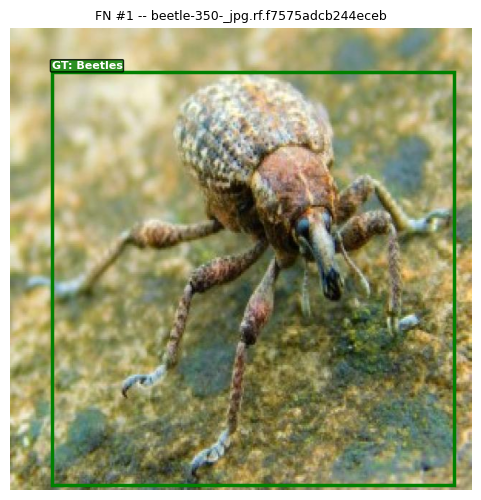


  FN 2: beetle-49-_jpg.rf.64cf115b7a2cf5df4b2a91e7411 -- GT: Beetles


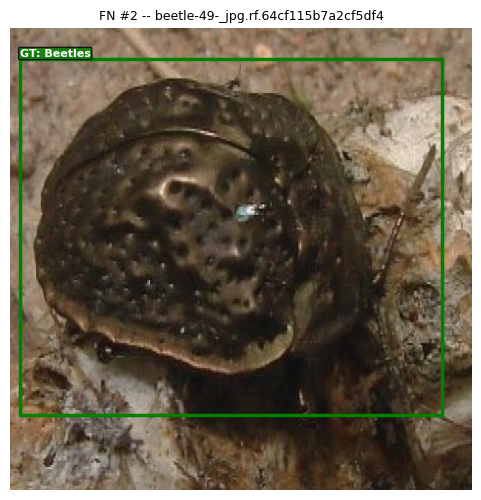


  FN 3: snail-372-_jpg.rf.d49979467c0d35aa76da55a8ad1 -- GT: Snails


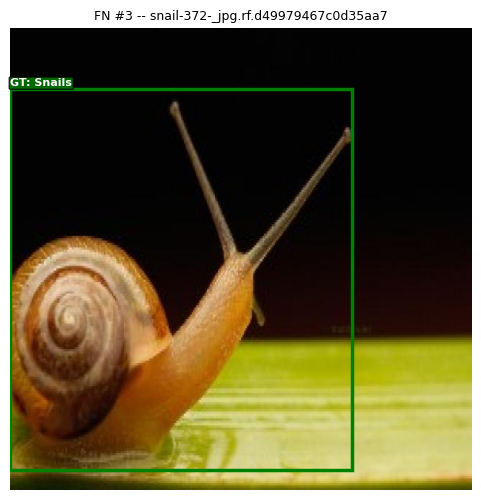


───────────────────────────────────────────────────────
  TOP 3 FALSE POSITIVES (highest confidence)
───────────────────────────────────────────────────────

  FP 1: beetle-350-_jpg.rf.f7575adcb244eceb3a667561d6 -- Pred: Weevils (conf=0.885)
         GT class: Beetles -- MISCLASSIFICATION


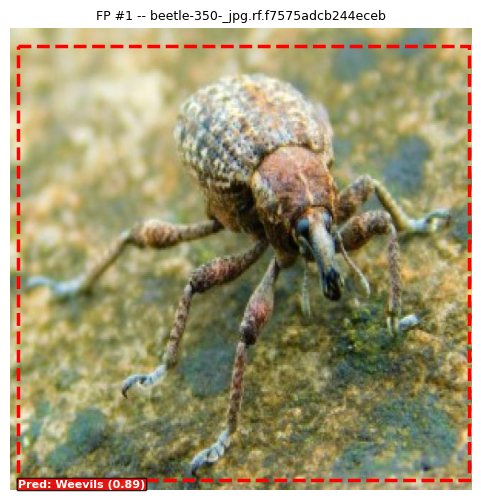


  FP 2: catterpillar-17-_jpg.rf.d431eb89c49c05f99f828 -- Pred: Slugs (conf=0.866)
         GT class: Caterpillars -- MISCLASSIFICATION


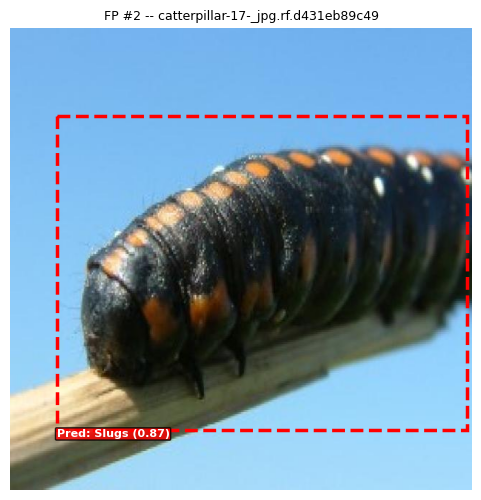


  FP 3: slug-206-_jpg.rf.feabb40ab1bcedba27b50db32834 -- Pred: Snails (conf=0.856)
         BACKGROUND -- no GT match


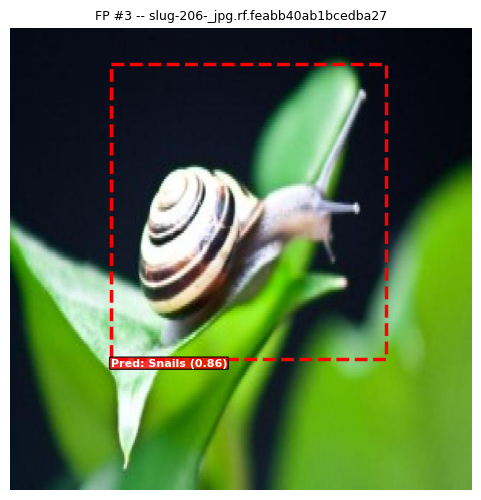

In [15]:
model = YOLO(best_model_path)

# ---- Run inference on test set (save=False for speed) ----
test_img_dir = os.path.join(CLEANED_PATH, "test", "images")
test_lbl_dir = os.path.join(CLEANED_PATH, "test", "labels")
test_img_list = sorted([f for f in os.listdir(test_img_dir)
                        if f.lower().endswith(('.jpg','.jpeg','.png'))])

preds = model.predict(
    source=test_img_dir,
    imgsz=IMGSZ,
    device=DEVICE,
    conf=CONF,
    iou=IOU,
    max_det=MAX_DET,
    verbose=False,
    save=False,
)

# ---- IoU helper ----
def compute_iou(boxA, boxB):
    """box = [x1, y1, x2, y2] in absolute pixels."""
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])
    interArea = max(0, xB - xA) * max(0, yB - yA)
    if interArea == 0:
        return 0.0
    boxAArea = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])
    return interArea / float(boxAArea + boxBArea - interArea)


# ---- Classify errors: FN, FP-bg, FP-miscls, LocErr ----
fn_examples   = []  # (img_path, gt_box_abs, gt_class_name, fname)
fp_bg         = []  # (img_path, pred_box_abs, pred_cls_name, pred_conf, fname)
fp_miscls     = []  # (img_path, pred_box_abs, pred_cls_name, gt_cls_name, pred_conf, fname)
locerr        = []  # (img_path, pred_box_abs, pred_cls_name, gt_box_abs, iou, pred_conf, fname)

for pred_result, fname in zip(preds, test_img_list):
    img_path = os.path.join(test_img_dir, fname)
    lbl_path = os.path.join(test_lbl_dir, os.path.splitext(fname)[0] + '.txt')
    if not os.path.exists(lbl_path):
        continue

    img = cv2.imread(img_path)
    if img is None:
        continue
    h, w = img.shape[:2]

    # Parse ground truth
    gt_boxes = []  # [(cls, x1, y1, x2, y2)]
    with open(lbl_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cls = int(float(parts[0]))
            cx, cy, bw, bh = map(float, parts[1:5])
            x1 = int((cx - bw / 2) * w)
            y1 = int((cy - bh / 2) * h)
            x2 = int((cx + bw / 2) * w)
            y2 = int((cy + bh / 2) * h)
            gt_boxes.append((cls, x1, y1, x2, y2))

    # Parse predictions
    pred_boxes = []  # [(cls, conf, x1, y1, x2, y2)]
    if pred_result.boxes is not None:
        for box_data in pred_result.boxes.data.cpu().numpy():
            x1, y1, x2, y2, conf, cls = box_data
            pred_boxes.append((int(cls), float(conf),
                               int(x1), int(y1), int(x2), int(y2)))

    # Greedy matching: pred -> GT, class-must-match for TP
    matched_gt   = set()
    matched_pred = set()
    best_match_for_pred = {}  # pi -> (gi, best_iou)

    pred_boxes_sorted = sorted(pred_boxes, key=lambda x: x[1], reverse=True)
    for pi, (pcls, pconf, px1, py1, px2, py2) in enumerate(pred_boxes_sorted):
        best_iou = 0.0
        best_gi  = -1
        best_gcls = -1
        for gi, (gcls, gx1, gy1, gx2, gy2) in enumerate(gt_boxes):
            if gi in matched_gt:
                continue
            iou = compute_iou([px1, py1, px2, py2], [gx1, gy1, gx2, gy2])
            if iou > best_iou:
                best_iou = iou
                best_gi  = gi
                best_gcls = gcls
        best_match_for_pred[pi] = (best_gi, best_iou, best_gcls)

        if best_iou >= 0.5 and best_gcls == pcls:
            # TP -- class matches
            matched_gt.add(best_gi)
            matched_pred.add(pi)
            
        elif best_iou >= 0.5 and best_gcls != pcls:
            # Misclassification -- right location, wrong class
            fp_miscls.append((img_path, (px1, py1, px2, py2),
                               CLASS_NAMES[pcls], CLASS_NAMES[best_gcls],
                               pconf, fname))
            matched_pred.add(pi)
            
        elif 0.3 <= best_iou < 0.5 and best_gcls == pcls:
            # Localization error -- right class, poor IoU
            # FIXED: Added 'gcls' to unpack all 5 elements
            gcls, gx1, gy1, gx2, gy2 = gt_boxes[best_gi]
            locerr.append((img_path, (px1, py1, px2, py2),
                            CLASS_NAMES[pcls], (gx1, gy1, gx2, gy2),
                            best_iou, pconf, fname))
            matched_pred.add(pi)

    # Unmatched GT boxes -> FN
    for gi, (gcls, gx1, gy1, gx2, gy2) in enumerate(gt_boxes):
        if gi not in matched_gt:
            fn_examples.append((img_path, (gx1, gy1, gx2, gy2),
                                CLASS_NAMES[gcls], fname))

    # Unmatched pred boxes -> FP (background)
    for pi, (pcls, pconf, px1, py1, px2, py2) in enumerate(pred_boxes_sorted):
        if pi not in matched_pred:
            fp_bg.append((img_path, (px1, py1, px2, py2),
                          CLASS_NAMES[pcls], pconf, fname))

# ---- Summary ----
print(f"\n{'='*55}")
print(f"  ERROR ANALYSIS SUMMARY")
print(f"  {'─'*40}")
print(f"  False Negatives (FN):                {len(fn_examples):>5}")
print(f"  False Positives -- Background:       {len(fp_bg):>5}")
print(f"  False Positives -- Misclassification: {len(fp_miscls):>5}")
print(f"  Localization Errors (LocErr):        {len(locerr):>5}")
print(f"{'='*55}")

# ---- Sort: FN by area (largest first), FP by confidence (highest first) ----
fn_examples.sort(key=lambda x: (x[1][2]-x[1][0])*(x[1][3]-x[1][1]), reverse=True)
fp_all = fp_bg + fp_miscls

# FIXED: Sorting by the second-to-last index to handle both 5-item and 6-item tuples
fp_all.sort(key=lambda x: x[-2], reverse=True)

# ---- Visualise ----
def draw_error_image(img_path, gt_box=None, gt_label=None,
                     pred_box=None, pred_label=None, pred_conf=None,
                     error_type="FN"):
    """Draw GT (green) and/or prediction (red dashed) on image."""
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    ax.imshow(img)

    if gt_box is not None:
        x1, y1, x2, y2 = gt_box
        rect = mpatches.Rectangle((x1, y1), x2-x1, y2-y1,
                                  fill=False, edgecolor='green', linewidth=2.5)
        ax.add_patch(rect)
        if gt_label:
            ax.text(x1, max(y1-4, 6), f"GT: {gt_label}",
                    fontsize=8, color='white', weight='bold',
                    bbox=dict(boxstyle='round,pad=0.1',
                              facecolor='green', alpha=0.8))

    if pred_box is not None:
        x1p, y1p, x2p, y2p = pred_box
        rect_p = mpatches.Rectangle((x1p, y1p), x2p-x1p, y2p-y1p,
                                     fill=False, edgecolor='red',
                                     linewidth=2.5, linestyle='--')
        ax.add_patch(rect_p)
        if pred_label:
            lbl = f"Pred: {pred_label}"
            if pred_conf is not None:
                lbl += f" ({pred_conf:.2f})"
            ax.text(x1p, max(y2p+10, 6), lbl,
                    fontsize=8, color='white', weight='bold',
                    bbox=dict(boxstyle='round,pad=0.1',
                              facecolor='red', alpha=0.8))

    ax.set_title(f"{error_type} -- {os.path.basename(img_path)[:35]}", fontsize=9)
    ax.axis('off')
    return fig


TOP_N = 3

# ---- False Negatives ----
print(f"\n{'─'*55}")
print(f"  TOP {TOP_N} FALSE NEGATIVES (largest missed objects by area)")
print(f"{'─'*55}")
for i in range(min(TOP_N, len(fn_examples))):
    img_path, gt_box, gt_cls_name, fname = fn_examples[i]
    print(f"\n  FN {i+1}: {fname[:45]} -- GT: {gt_cls_name}")
    fig = draw_error_image(img_path, gt_box=gt_box, gt_label=gt_cls_name,
                           error_type=f"FN #{i+1}")
    plt.show()
    plt.close(fig)

# ---- False Positives (combined background + misclassification) ----
print(f"\n{'─'*55}")
print(f"  TOP {TOP_N} FALSE POSITIVES (highest confidence)")
print(f"{'─'*55}")
for i in range(min(TOP_N, len(fp_all))):
    if len(fp_all[i]) == 6:
        # FP-miscls
        img_path, pred_box, pred_cls, gt_cls, pred_conf, fname = fp_all[i]
        print(f"\n  FP {i+1}: {fname[:45]} -- Pred: {pred_cls} (conf={pred_conf:.3f})")
        print(f"         GT class: {gt_cls} -- MISCLASSIFICATION")
    else:
        # FP-bg
        img_path, pred_box, pred_cls, pred_conf, fname = fp_all[i]
        print(f"\n  FP {i+1}: {fname[:45]} -- Pred: {pred_cls} (conf={pred_conf:.3f})")
        print(f"         BACKGROUND -- no GT match")
    fig = draw_error_image(img_path, pred_box=pred_box,
                           pred_label=pred_cls, pred_conf=pred_conf,
                           error_type=f"FP #{i+1}")
    plt.show()
    plt.close(fig)

# Save Checkpoint

Copy the best checkpoint to `/kaggle/working/` for download or cross-model
comparison (Notebook 2-4 will also save to this directory).

In [16]:
import shutil

src = os.path.join(PROJECT, RUN_NAME, "weights", "best.pt")
dst = os.path.join("/kaggle/working", "yolov26_agropest_best.pt")

if os.path.exists(src):
    shutil.copy(src, dst)
    size_mb = os.path.getsize(dst) / (1024**2)
    print(f"Checkpoint saved: {dst}")
    print(f"  Size: {size_mb:.1f} MB")
else:
    print(f"Source not found: {src}")

Checkpoint saved: /kaggle/working/yolov26_agropest_best.pt
  Size: 42.0 MB
